# Classification Track — Insurance Claims Fraud Detection
**23CSE301 Machine Learning Capstone — Review 1 (Part A) + Review 2 (Part B)**

**Dataset:** `data/insurance_claims/insurance_claims.csv` (1,000 rows x 40 columns) — auto-insurance policy and incident records.

**Problem statement:** Predict **`fraud_reported`** (Yes/No) — whether an insurance claim is fraudulent — from policy, customer and incident attributes.

**Scope of this notebook:**

*Review 1 — Part A*
1. Data loading & audit
2. Exploratory Data Analysis (EDA)
3. Data cleaning, feature engineering, encoding, scaling, splitting
4. **Dimensionality reduction (PCA)** — fit on the training split, then used as the shared preprocessing for every Part-A algorithm
5. Training & evaluating the **Part-A algorithms**: Logistic Regression, K-Nearest Neighbors, Naive Bayes (Gaussian), Decision Tree, SVC
6. Preliminary comparison table (Accuracy, weighted F1, confusion matrix)

*Review 2 — Part B* (Sections E–I, after the Part-A demo)

7. Training the **Part-B algorithms** on the *same* split and pipeline: Random Forest, AdaBoost, Gradient Boosting, Bagging (Decision Tree base), MLP Classifier
8. **Consolidated 10-algorithm comparison table** (Accuracy, Precision, Recall, F1, ROC-AUC) + ROC curves for all ten
9. Diagnostic: **PCA vs. original encoded features** — why tree ensembles need the raw one-hot features
10. **Hyperparameter tuning** (`GridSearchCV`) for all 10 algorithms, with the feature representation itself treated as a hyperparameter
11. **Final model selection**, 5-fold cross-validation of the two best models, feature importance, and saved models

**Random seed** `42` is used everywhere for reproducibility.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams['figure.dpi'] = 100

DATA_PATH = '../data/insurance_claims/insurance_claims.csv'

## Section A — Dataset Loading & Audit (A1)

In [2]:
df = pd.read_csv(DATA_PATH)

print(f'Shape: {df.shape[0]} rows x {df.shape[1]} columns')
print()
print('Data types:')
print(df.dtypes.value_counts())

Shape: 1000 rows x 40 columns

Data types:
object     21
int64      17
float64     2
Name: count, dtype: int64


In [3]:
# The raw CSV encodes missing categorical values as the literal string '?'; convert to NaN
# so pandas/sklearn treat them as proper missing values.
df = df.replace('?', np.nan)

missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print('Columns with missing values:')
print(missing)

print(f'\nDuplicate rows: {df.duplicated().sum()}')

print('\nTarget (fraud_reported) class distribution:')
print(df['fraud_reported'].value_counts())
print(df['fraud_reported'].value_counts(normalize=True).round(3))

Columns with missing values:
_c39                       1000
property_damage             360
police_report_available     343
collision_type              178
authorities_contacted        91
dtype: int64

Duplicate rows: 0

Target (fraud_reported) class distribution:
fraud_reported
N    753
Y    247
Name: count, dtype: int64
fraud_reported
N    0.753
Y    0.247
Name: proportion, dtype: float64


**Observation:** The dataset has 1,000 rows and 40 columns. `_c39` is a completely empty stray column (an artifact of the CSV export) and will be dropped. Four genuine categorical columns — `collision_type`, `property_damage`, `police_report_available`, `authorities_contacted` — have missing values that were originally encoded as `'?'`. There are no duplicate rows. The target `fraud_reported` is **imbalanced** (~75% "N" / ~25% "Y"), so a stratified split and weighted/F1-based metrics (rather than accuracy alone) are used throughout.

## Section A — EDA Visualisations (A2)

### A2.1 Distribution of every numeric feature

16 numeric columns plotted, 17 categorical columns plotted


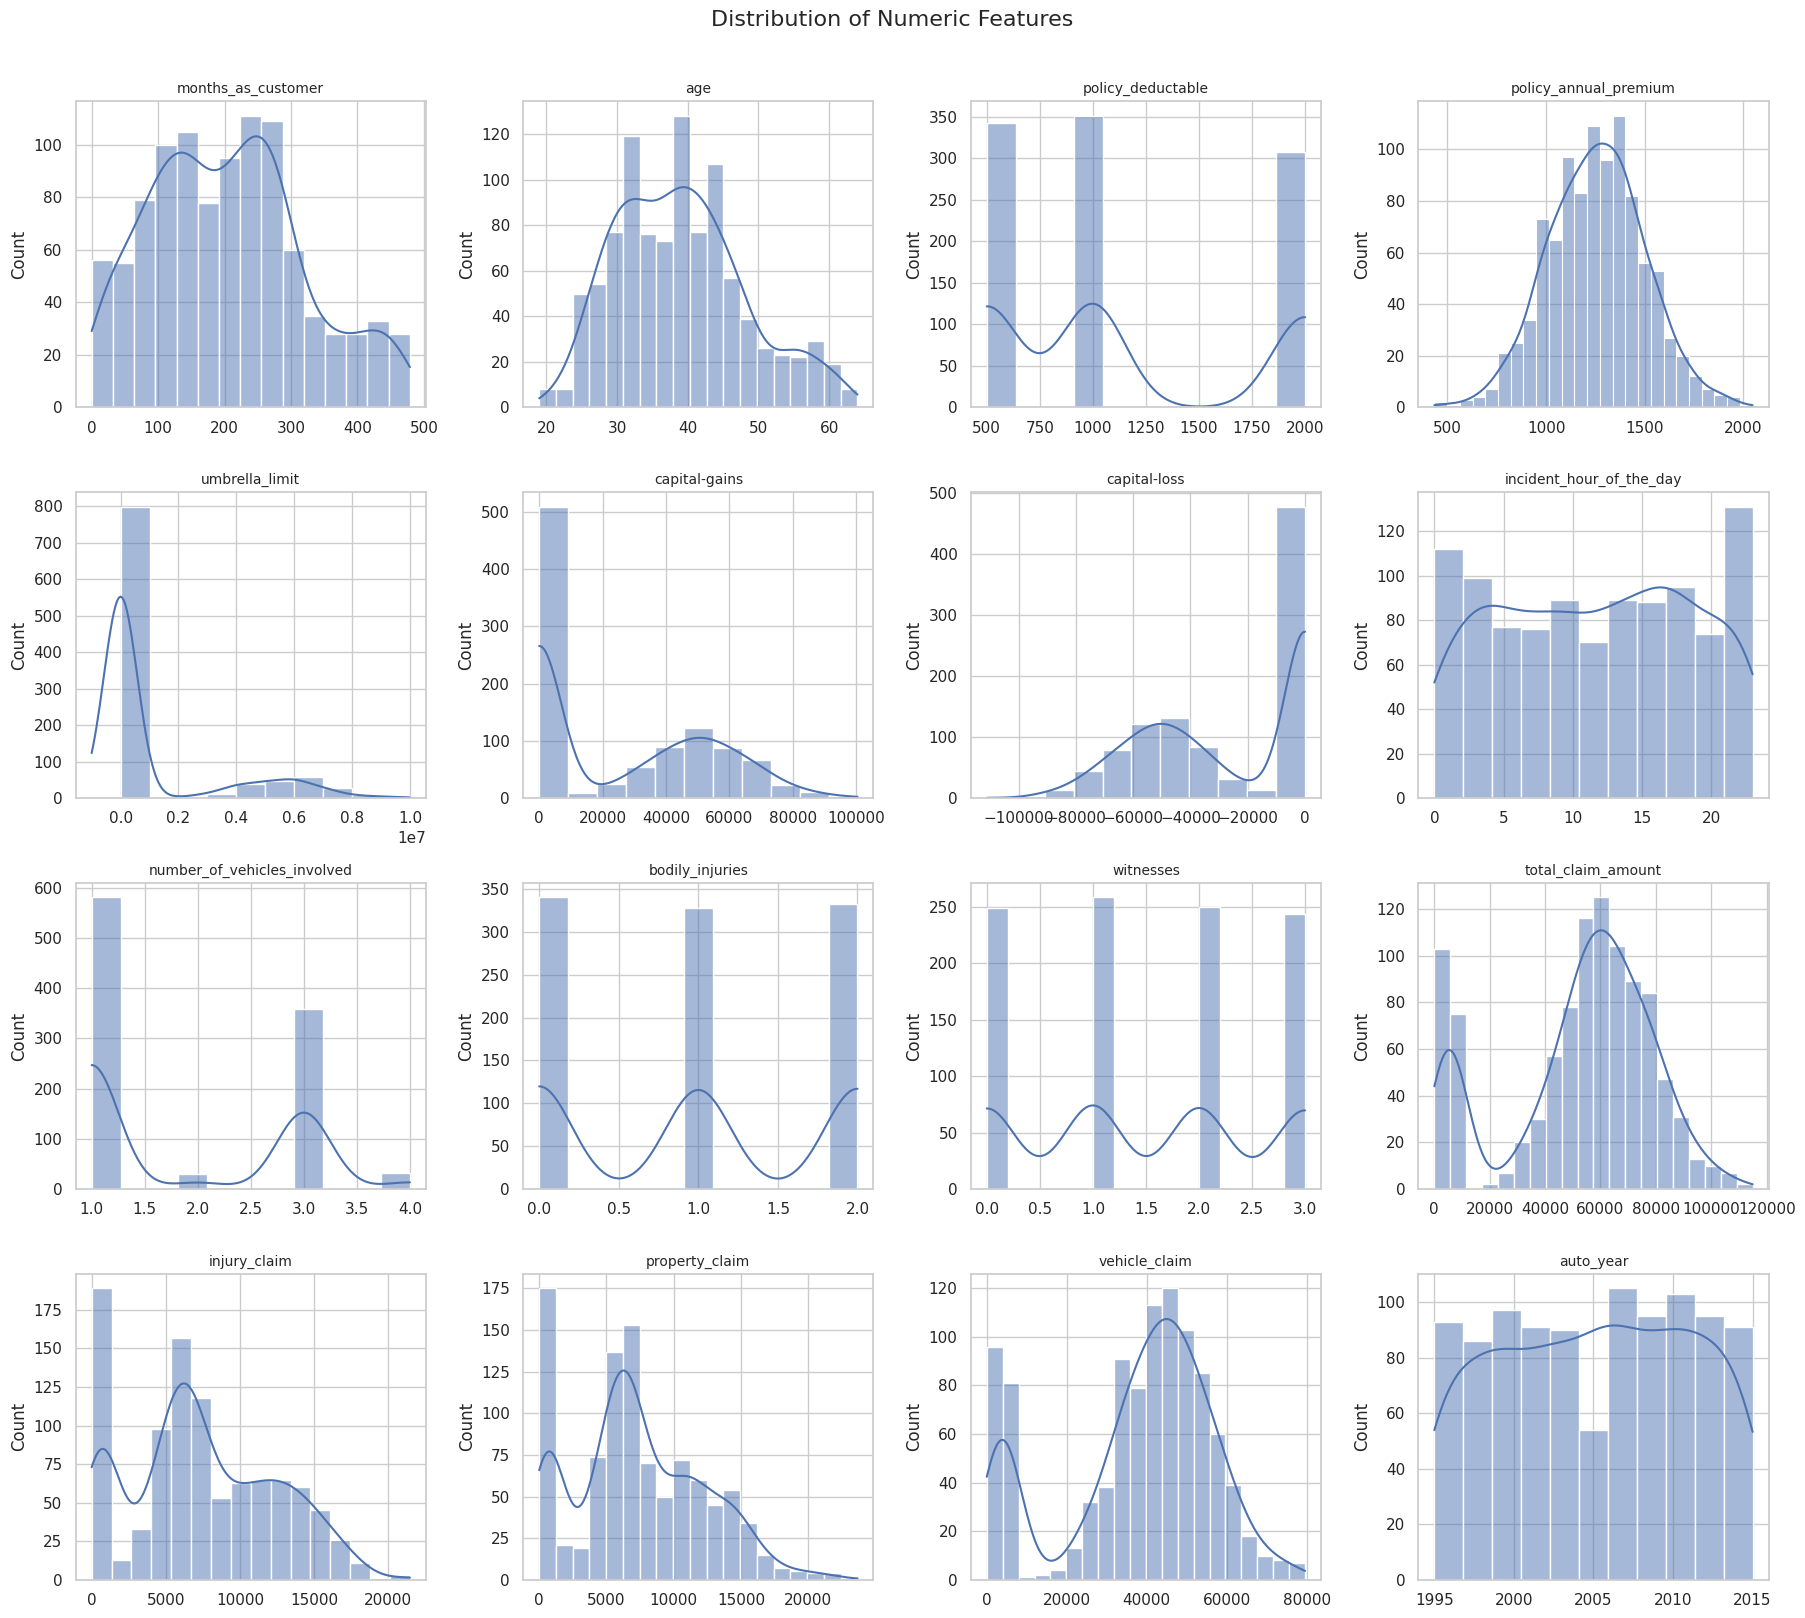

In [4]:
id_like_cols = ['policy_number', 'insured_zip', '_c39']  # identifiers / empty column, not distributions of interest
numeric_cols = [c for c in df.select_dtypes(include=np.number).columns if c not in id_like_cols]
categorical_cols = [c for c in df.select_dtypes(include='object').columns
                     if c not in ['fraud_reported', '_c39', 'policy_bind_date', 'incident_date', 'incident_location']]

print(f'{len(numeric_cols)} numeric columns plotted, {len(categorical_cols)} categorical columns plotted')

fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color='#4C72B0')
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('')
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])
fig.suptitle('Distribution of Numeric Features', fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig('../models/clf_numeric_distributions.png', bbox_inches='tight')
plt.show()

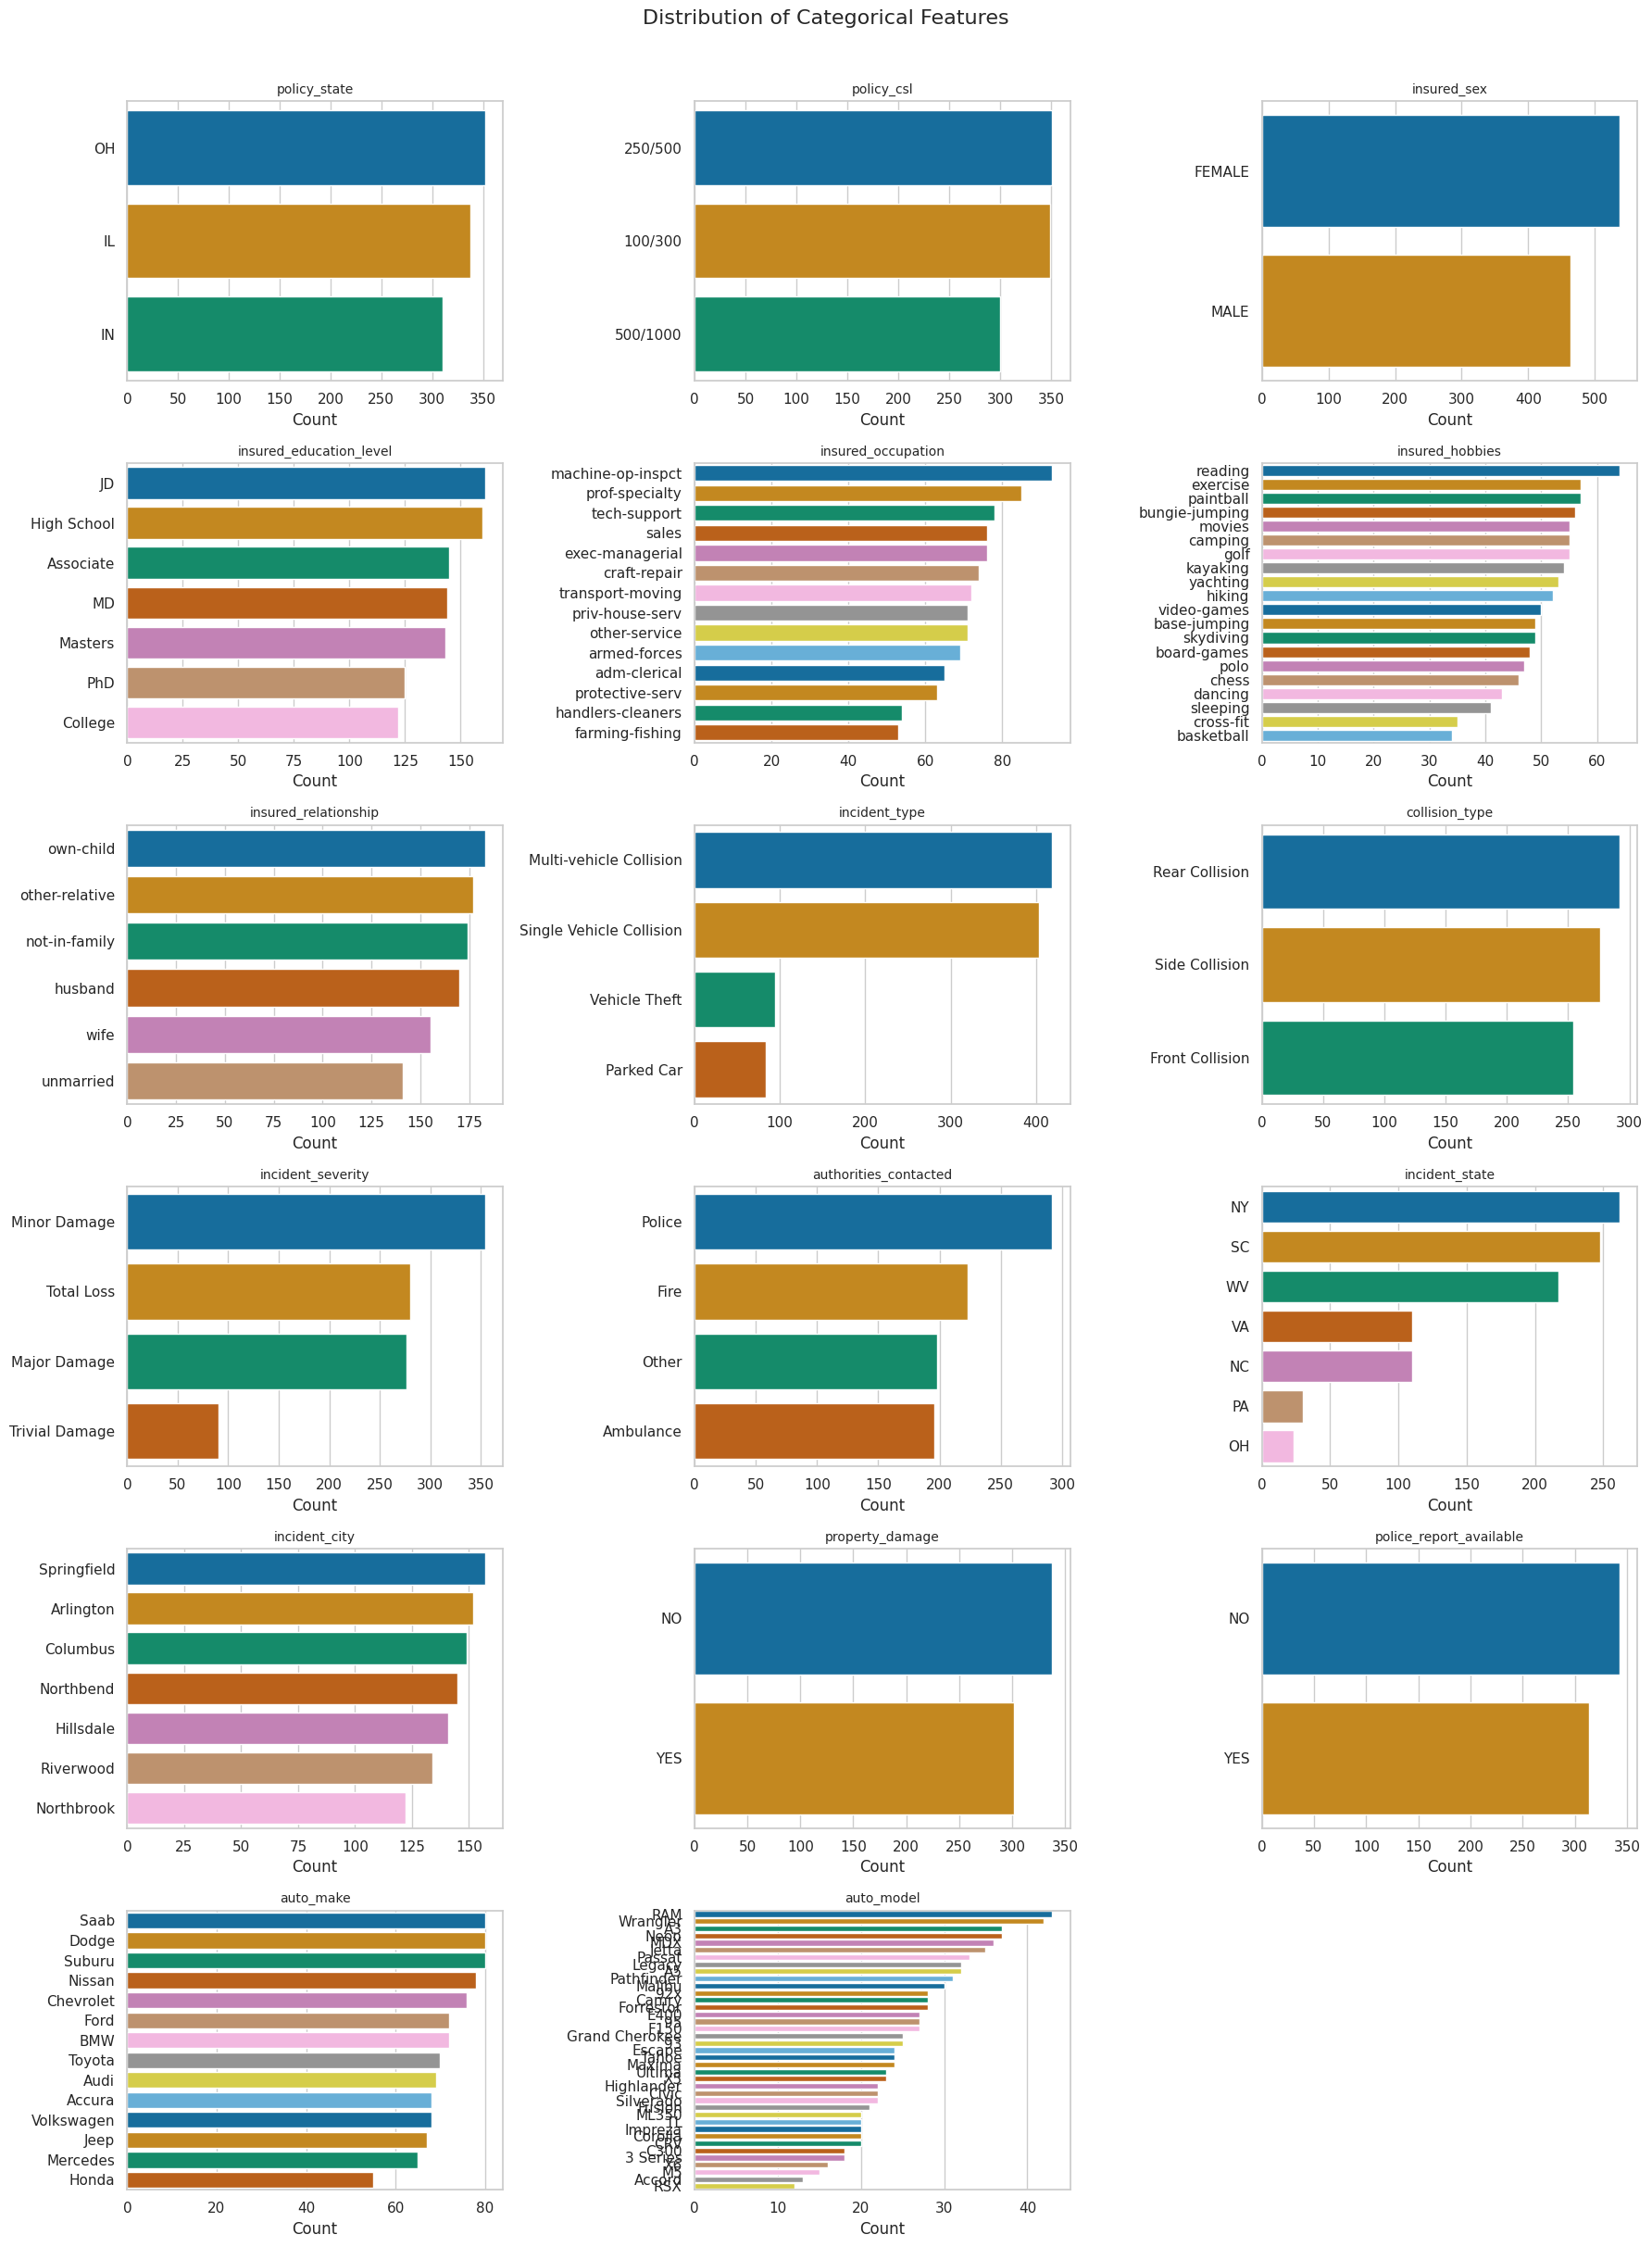

In [5]:
n_cat = len(categorical_cols)
ncols = 3
nrows = int(np.ceil(n_cat / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows))
axes = axes.flatten()
for i, col in enumerate(categorical_cols):
    order = df[col].value_counts().index
    sns.countplot(y=df[col], order=order, ax=axes[i], palette='colorblind')
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('Count')
    axes[i].set_ylabel('')
for j in range(n_cat, len(axes)):
    fig.delaxes(axes[j])
fig.suptitle('Distribution of Categorical Features', fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig('../models/clf_categorical_distributions.png', bbox_inches='tight')
plt.show()

**Observation:** Claim amounts (`total_claim_amount`, `injury_claim`, `property_claim`, `vehicle_claim`) are right-skewed, as expected for monetary values, and `total_claim_amount` is (by construction) close to the sum of the other three claim components. `incident_severity` and `insured_hobbies` show highly uneven category frequencies — a small number of hobbies (e.g. "chess", "cross-fit") appear much less often than common ones, which is worth watching for during modelling since rare categories can behave like near-identifiers.

### A2.2 Correlation heatmap

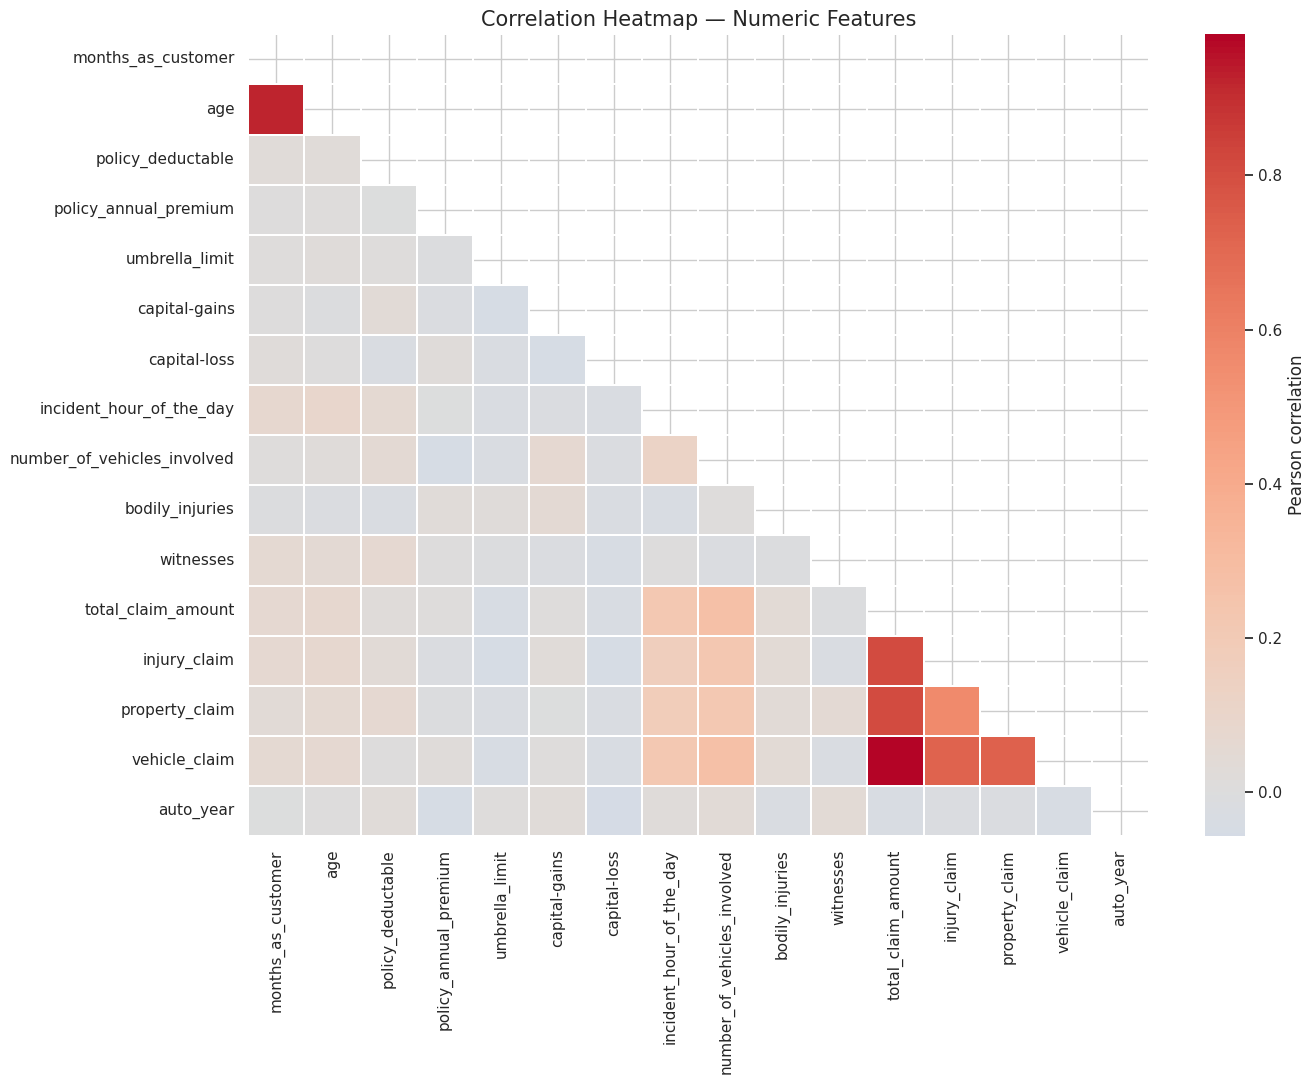

In [6]:
plt.figure(figsize=(14, 11))
corr = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, annot=False, linewidths=0.3, cbar_kws={'label': 'Pearson correlation'})
plt.title('Correlation Heatmap — Numeric Features', fontsize=15)
plt.tight_layout()
plt.savefig('../models/clf_correlation_heatmap.png', bbox_inches='tight')
plt.show()

**Observation:** As expected, `total_claim_amount` is strongly correlated with its three components `injury_claim`, `property_claim`, `vehicle_claim` (multicollinearity), which is a consideration for the Logistic Regression model in particular. Most other numeric features are weakly correlated with each other, so no further numeric features need to be dropped for redundancy.

### A2.3 Target distribution

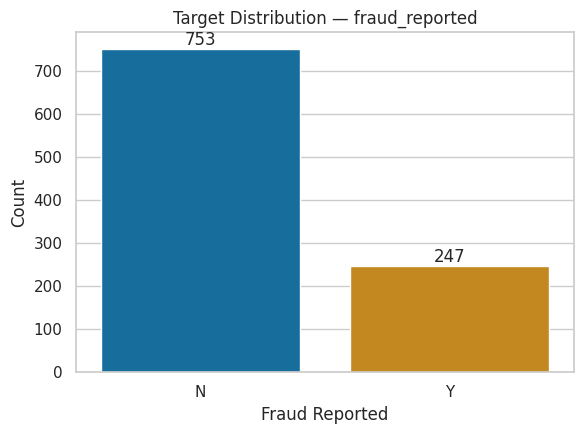

In [7]:
plt.figure(figsize=(6, 4.5))
ax = sns.countplot(x=df['fraud_reported'], order=['N', 'Y'], palette='colorblind')
ax.set_title('Target Distribution — fraud_reported')
ax.set_xlabel('Fraud Reported')
ax.set_ylabel('Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.tight_layout()
plt.savefig('../models/clf_target_distribution.png', bbox_inches='tight')
plt.show()

**Observation:** The classes are imbalanced (753 "N" vs 247 "Y", ~3:1). This is not extreme enough to require resampling (SMOTE/undersampling), but it does mean **accuracy alone would be misleading** (a model predicting "N" for everyone would score 75.3% accuracy) — hence Accuracy is reported alongside weighted Precision/Recall/F1, the confusion matrix and ROC-AUC.

### A2.4 Feature–target relationships (>= 2 plots)